<a href="https://colab.research.google.com/github/scorreal25/ProyectoProgramacion/blob/main/PROYECTO_FINAL_SPOTIFY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Factores clave en el éxito musical
## Características de audio y popularidad en las canciones más escuchadas de Spotify (2023)

Proyecto final (Opción B)

Integrantes: Martina Ramírez, Valeria Vega, Alejandro Simon Reyes y Sofía Correal

Pregunta: ¿Cómo se relacionan el ritmo (BPM), la bailabilidad y la energía de una canción con su número de reproducciones en Spotify? ¿Qué tienen en común las canciones más escuchadas? Y, como pregunta adicional: ¿en qué mes de lanzamiento se concentran las canciones con más reproducciones?

**Fuente de los datos:** Kaggle, *Most Streamed Spotify Songs 2023* (usuario nelgiriyewithana): https://www.kaggle.com/datasets/nelgiriyewithana/top-spotify-songs-2023

## 1. Librerías

In [1]:
#Escogemos las librerias que necesitamos

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Cargar y explorar los datos

In [2]:
from google.colab import files
subidos = files.upload()   # selecciona spotify-2023.csv

df = pd.read_csv('spotify-2023_3.csv', encoding='latin-1')
print(df.shape)
df.head()

Saving spotify-2023_3.csv to spotify-2023_3.csv
(953, 24)


,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,...,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,2023,7,14,553,147,141381703,43,...,125,B,Major,80,89,83,31,0,8,4
1,LALA,Myke Towers,1,2023,3,23,1474,48,133716286,48,...,92,C#,Major,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,1,2023,6,30,1397,113,140003974,94,...,138,F,Major,51,32,53,17,0,31,6
3,Cruel Summer,Taylor Swift,1,2019,8,23,7858,100,800840817,116,...,170,A,Major,55,58,72,11,0,11,15
4,WHERE SHE GOES,Bad Bunny,1,2023,5,18,3133,50,303236322,84,...,144,A,Minor,65,23,80,14,63,11,6




**Observación:** la columna de streams (reproducciones) aparece como texto y no como número. Eso indica que hay al menos un valor mal escrito.

In [3]:
# Revisamos el tipo de dato de cada columna y cuántos valores faltantes hay
print(df.dtypes)
print()
print('Datos faltantes por columna:')
print(df.isna().sum())

track_name              object
artist(s)_name          object
artist_count             int64
released_year            int64
released_month           int64
released_day             int64
in_spotify_playlists     int64
in_spotify_charts        int64
streams                 object
in_apple_playlists       int64
in_apple_charts          int64
in_deezer_playlists     object
in_deezer_charts         int64
in_shazam_charts        object
bpm                      int64
key                     object
mode                    object
danceability_%           int64
valence_%                int64
energy_%                 int64
acousticness_%           int64
instrumentalness_%       int64
liveness_%               int64
speechiness_%            int64
dtype: object

Datos faltantes por columna:
track_name               0
artist(s)_name           0
artist_count             0
released_year            0
released_month           0
released_day             0
in_spotify_playlists     0
in_spotify_charts      

## 3. Preparación de los datos

Quitar columnas que no necesitamos


In [4]:
#Eliminamos las columnas de Apple, Deezer y Shazam
df = df.drop(columns=[
    'in_apple_playlists', 'in_apple_charts', 'in_deezer_playlists',
    'in_deezer_charts', 'in_shazam_charts', 'in_spotify_charts',
    'instrumentalness_%', 'liveness_%'
], errors='ignore')

print(df.columns)

Index(['track_name', 'artist(s)_name', 'artist_count', 'released_year',
       'released_month', 'released_day', 'in_spotify_playlists', 'streams',
       'bpm', 'key', 'mode', 'danceability_%', 'valence_%', 'energy_%',
       'acousticness_%', 'speechiness_%'],
      dtype='object')


### 3.2 Corregir la columna `streams`


In [5]:
# Identificamos filas con 'streams' no numérico, las eliminamos y convertimos la columna a entero

es_numero = df['streams'].apply(lambda x: x.isdigit())

print('Fila con streams inválido:')
print(df[es_numero == False][['track_name', 'artist(s)_name', 'streams']])

# nos quedamos solo con las filas válidas (.copy() crea una tabla nueva e independiente)

df = df[es_numero].copy()

# texto = número entero
df['streams'] = df['streams'].apply(int)
print()
print('Canciones después de limpiar:', df.shape[0])

Fila con streams inválido:
                              track_name     artist(s)_name  \
574  Love Grows (Where My Rosemary Goes)  Edison Lighthouse   

                                               streams  
574  BPM110KeyAModeMajorDanceability53Valence75Ener...  

Canciones después de limpiar: 952


### 3.3 Datos faltantes en key (tono)
95 canciones no tienen tono registrado. No las borramos (perderíamos el 10% de la base): las rellenamos con fillna('Sin dato')`.

In [6]:
df['key'] = df['key'].fillna('Sin dato')
print(df['key'].value_counts())

key
C#          120
G            96
Sin dato     95
G#           91
F            89
B            81
D            81
A            74
F#           73
E            62
A#           57
D#           33
Name: count, dtype: int64


### 3.4 Nuevas columnas


In [7]:
#Ponemos las reproducciones en millones, para que los números sean más fáciles de leer
df['streams_millones'] = df['streams'] / 1000000

#Hacemos un promedio entre la danceabilidad y la energía, los resumimos en un solo numero
df['baile_energia'] = (df['danceability_%'] + df['energy_%']) / 2
df[['track_name', 'streams_millones', 'danceability_%', 'energy_%', 'baile_energia']].head()

,track_name,streams_millones,danceability_%,energy_%,baile_energia
0,Seven (feat. Latto) (Explicit Ver.),141.381703,80,83,81.5
1,LALA,133.716286,71,74,72.5
2,vampire,140.003974,51,53,52.0
3,Cruel Summer,800.840817,55,72,63.5
4,WHERE SHE GOES,303.236322,65,80,72.5


## 4. Análisis
### 4.1 Panorama general

In [8]:
resumen = df['streams_millones'].describe()
resumen

,streams_millones
count,952.000000
mean,514.137425
std,566.856949
min,0.002762
25%,141.636175
50%,290.530915
75%,673.869022
max,3703.895074


In [9]:
top5 = df.sort_values('streams', ascending=False).head(5)
top5[['track_name', 'artist(s)_name', 'released_year', 'streams_millones']]

,track_name,artist(s)_name,released_year,streams_millones
55,Blinding Lights,The Weeknd,2019,3703.895074
179,Shape of You,Ed Sheeran,2017,3562.543890
86,Someone You Loved,Lewis Capaldi,2018,2887.241814
620,Dance Monkey,Tones and I,2019,2864.791672
41,Sunflower - Spider-Man: Into the Spider-Verse,"Post Malone, Swae Lee",2018,2808.096550


### 4.2 Clasificar las canciones en 4 grupos según sus reproducciones


In [10]:
#Extraer los valores de los cuartiles (25%, 50% y 75%) del resumen estadístico
limite_25 = resumen['25%']
limite_50 = resumen['50%']
limite_75 = resumen['75%']

#Definir función para categorizar cada registro según su volumen de streams
def clasificar_popularidad(millones):
    if millones <= limite_25:
        return 'Bajo'
    elif millones <= limite_50:
        return 'Medio-bajo'
    elif millones <= limite_75:
        return 'Medio-alto'
    else:
        return 'Top 25%'
# Crear la nueva columna aplicando la clasificación y verificar el conteo por grupo
df['grupo'] = df['streams_millones'].apply(clasificar_popularidad)
print(df['grupo'].value_counts())

grupo
Bajo          238
Top 25%       238
Medio-alto    238
Medio-bajo    238
Name: count, dtype: int64


### 4.3 ¿Qué tienen en común las canciones de cada grupo?


In [11]:
tabla_grupos = df.groupby('grupo').agg(
    canciones=('streams', 'count'),
    streams_millones=('streams_millones', 'median'),
    bpm=('bpm', 'median'),
    bailabilidad=('danceability_%', 'median'),
    energia=('energy_%', 'median'),
    baile_energia=('baile_energia', 'median'),
    playlists_spotify=('in_spotify_playlists', 'median'),
)
tabla_grupos = tabla_grupos.loc[['Bajo', 'Medio-bajo', 'Medio-alto', 'Top 25%']]
tabla_grupos.round(1)

,canciones,streams_millones,bpm,bailabilidad,energia,baile_energia,playlists_spotify
grupo,,,,,,,
Bajo,238,85.7,121.5,70.0,67.0,68.2,729.0
Medio-bajo,238,200.8,124.0,70.0,66.5,69.0,1373.5
Medio-alto,238,419.1,120.0,70.0,64.0,67.5,3115.5
Top 25%,238,1190.9,118.0,65.0,65.5,65.5,10855.5


**observacion:** el BPM, la bailabilidad y la energía son casi iguales en los cuatro grupos. Lo que sí cambia bastante es el número de **playlists** de Spotify en las que está la canción

### 4.4 ¿Las más escuchadas son de tono mayor o menor?


In [12]:
#Indicamos si la canción está en tono mayor o menor
#Vemos el porcentaje de cada modo dentro de cada grupo
modo_por_grupo = pd.crosstab(df['grupo'], df['mode'], normalize='index') * 100
modo_por_grupo = modo_por_grupo.loc[['Bajo', 'Medio-bajo', 'Medio-alto', 'Top 25%']]
modo_por_grupo.round(1)

mode,Major,Minor
grupo,,
Bajo,51.7,48.3
Medio-bajo,59.7,40.3
Medio-alto,59.7,40.3
Top 25%,59.7,40.3


**Observación:** en los tres grupos más escuchados, el 60% de las canciones está en tono mayor  y en el grupo Bajo, el 52%. Es una diferencia pequeña: el tono tampoco separa claramente a los éxitos.

### 4.5 Perfil típico de un éxito (con NumPy)

In [13]:
print('BPM mediano:         ', np.median(df['bpm']))
print('Bailabilidad mediana:', np.median(df['danceability_%']), '%')
print('Energía mediana:     ', np.median(df['energy_%']), '%')

BPM mediano:          121.0
Bailabilidad mediana: 69.0 %
Energía mediana:      66.0 %


### 4.6 Histogramas: ¿qué BPM y qué energía son más comunes?


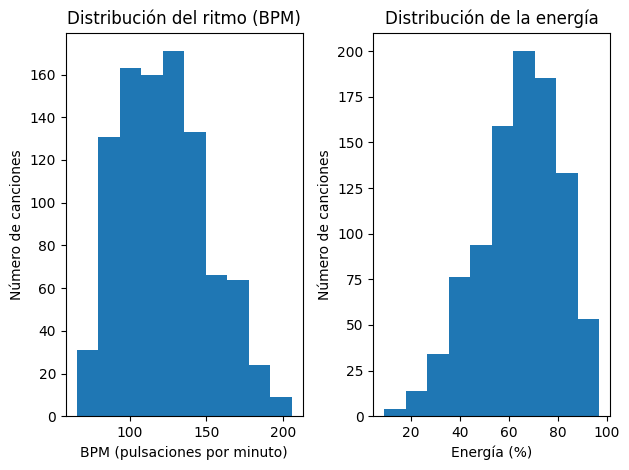

In [14]:
fig, axes = plt.subplots(1, 2)

axes[0].hist(df['bpm'])
axes[0].set_title('Distribución del ritmo (BPM)')
axes[0].set_xlabel('BPM (pulsaciones por minuto)')
axes[0].set_ylabel('Número de canciones')

axes[1].hist(df['energy_%'])
axes[1].set_title('Distribución de la energía')
axes[1].set_xlabel('Energía (%)')
axes[1].set_ylabel('Número de canciones')

plt.tight_layout()
plt.savefig('fig_histogramas.png')
plt.show()

### 4.7 Dispersión: características vs. reproducciones
 Si hubiera relación, los puntos formarían una línea inclinada. A la izquierda, baile-energía; a la derecha, el número de playlists, como comparación.

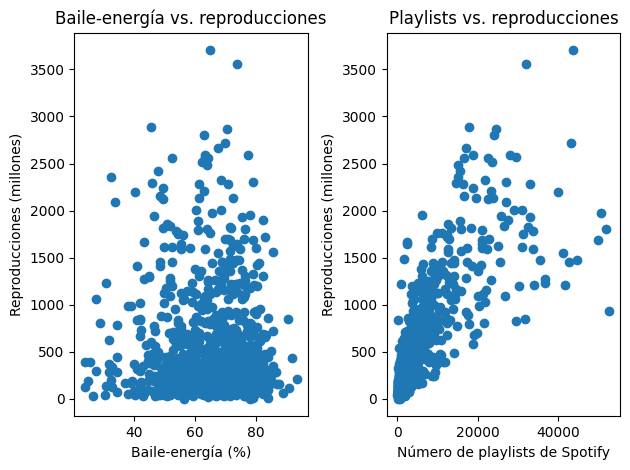

In [15]:
fig, axes = plt.subplots(1, 2)

axes[0].scatter(df['baile_energia'], df['streams_millones'])
axes[0].set_title('Baile-energía vs. reproducciones')
axes[0].set_xlabel('Baile-energía (%)')
axes[0].set_ylabel('Reproducciones (millones)')

axes[1].scatter(df['in_spotify_playlists'], df['streams_millones'])
axes[1].set_title('Playlists vs. reproducciones')
axes[1].set_xlabel('Número de playlists de Spotify')
axes[1].set_ylabel('Reproducciones (millones)')

plt.tight_layout()
plt.savefig('fig_dispersion.png')
plt.show()

**Observación:** en la gráfica de la izquierda los puntos forman una nube sin inclinación: tener más o menos baile-energía no se asocia con más reproducciones. En la de la derecha sí hay una tendencia clara: a más playlists, más reproducciones.

### 4.8 ¿En qué mes de lanzamiento se concentran más reproducciones?
*¿las canciones lanzadas en qué mes acumulan más reproducciones?*

Con `map` y un diccionario ponemos el nombre de cada mes.

In [16]:
nombres_meses = {1: 'Ene', 2: 'Feb', 3: 'Mar', 4: 'Abr', 5: 'May', 6: 'Jun',
                 7: 'Jul', 8: 'Ago', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dic'}

por_mes = df.groupby('released_month').agg(
    canciones=('streams', 'count'),
    total_millones=('streams_millones', 'sum'),
    mediana_millones=('streams_millones', 'median'),
)
por_mes.index = por_mes.index.map(nombres_meses)
por_mes.round(0)

,canciones,total_millones,mediana_millones
released_month,,,
Ene,133,96758.0,500.0
Feb,61,21542.0,234.0
Mar,86,41027.0,227.0
Abr,66,26674.0,202.0
May,128,53206.0,231.0
Jun,86,35264.0,171.0
Jul,62,29895.0,355.0
Ago,46,29038.0,427.0
Sep,56,41140.0,415.0


Enero estaba muy arriba. Revisamos por qué con un filtro: muchas canciones de enero tienen como fecha exacta el **1 de enero** y son de años anteriores. Probablemente es una fecha "de relleno" que se puso cuando no se conocía la fecha real.

In [17]:
enero = df[df['released_month'] == 1]
enero_1 = enero[enero['released_day'] == 1]
print('Canciones de enero:', enero.shape[0])
print('De esas, con fecha 1 de enero:', enero_1.shape[0])
print('Y de esas, lanzadas antes de 2022:', enero_1[enero_1['released_year'] < 2022].shape[0])

Canciones de enero: 133
De esas, con fecha 1 de enero: 64
Y de esas, lanzadas antes de 2022: 64


Además, las canciones viejas llevan más años sumando reproducciones. Para comparar meses de forma más justa, repetimos el cálculo solo con canciones de **2022 y 2023** (el 60% de la base) y graficamos las dos versiones en la misma gráfica de líneas.

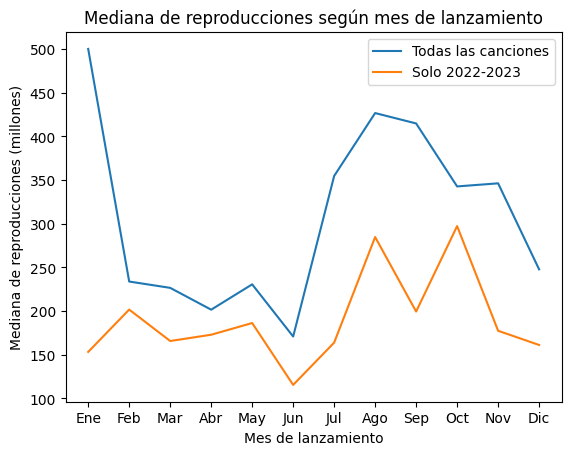

Canciones 2022-2023 por mes:
released_month
1      56
2      51
3      64
4      51
5     104
6      61
7      40
8      19
9      20
10     37
11     26
12     48
Name: count, dtype: int64


In [18]:
recientes = df[df['released_year'] >= 2022]

mediana_todas = df.groupby('released_month')['streams_millones'].median()
mediana_recientes = recientes.groupby('released_month')['streams_millones'].median()
meses = list(nombres_meses.values())

plt.plot(meses, mediana_todas.values, label='Todas las canciones')
plt.plot(meses, mediana_recientes.values, label='Solo 2022-2023')
plt.title('Mediana de reproducciones según mes de lanzamiento')
plt.xlabel('Mes de lanzamiento')
plt.ylabel('Mediana de reproducciones (millones)')
plt.legend()
plt.savefig('fig_meses.png')
plt.show()

print('Canciones 2022-2023 por mes:')
print(recientes['released_month'].value_counts().sort_index())

## 6. Nuestro uso de inteligencia artificial
- **Herramienta:** Claude (Anthropic).
- **Para qué la usamos:** organizar la estructura del notebook, encontrar por qué `streams` no era numérica y cómo leer el archivo con `encoding='latin-1'`, y apoyar la redacción de las explicaciones.
- **Cómo verificamos:** corrimos todas las celdas, revisamos a mano la fila con el valor inválido en `streams` y las fechas del 1 de enero, y comparamos las cifras de las conclusiones con las tablas del notebook. Las conclusiones las discutimos en grupo.